In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jawah\Downloads\project\telecochurn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,churn_flag,tenure_group
0,3447-DSKZQ,Male,0,No,No,57,No,No phone service,DSL,No,...,Yes,No,One year,No,Electronic check,40.05,2221.40,No,0,49+ months
1,3905-HDOFD,Male,0,No,No,25,Yes,No,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Mailed check,96.50,2497.76,No,0,25-48 months
2,4596-RVARX,Male,0,Yes,Yes,72,Yes,No,Fiber optic,Yes,...,Yes,No,Month-to-month,No,Electronic check,91.00,6646.49,No,0,49+ months
3,4365-QCTFX,Female,0,Yes,No,13,Yes,Yes,DSL,Yes,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),87.45,1089.88,No,0,13-24 months
4,5247-NHNSS,Female,0,No,No,6,No,No phone service,DSL,Yes,...,Yes,No,Month-to-month,Yes,Mailed check,53.15,323.69,Yes,1,0-12 months


In [2]:
print(df.shape)
print(df.isnull().sum())
df.describe()

(7043, 23)
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
churn_flag           0
tenure_group         0
dtype: int64


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,churn_flag
count,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000
mean,0.166690,32.339344,65.648843,2122.522063,0.264802
std,0.372726,23.136153,27.440701,1866.689959,0.441259
min,0.000000,0.000000,18.250000,17.480000,0.000000
25%,0.000000,11.000000,48.075000,587.187500,0.000000
50%,0.000000,28.000000,70.600000,1449.410000,0.000000
75%,0.000000,52.000000,88.500000,3407.097500,1.000000
max,1.000000,72.000000,118.400000,8010.730000,1.000000


Churn
No     5178
Yes    1865
Name: count, dtype: int64
Churn
No     73.519807
Yes    26.480193
Name: proportion, dtype: float64


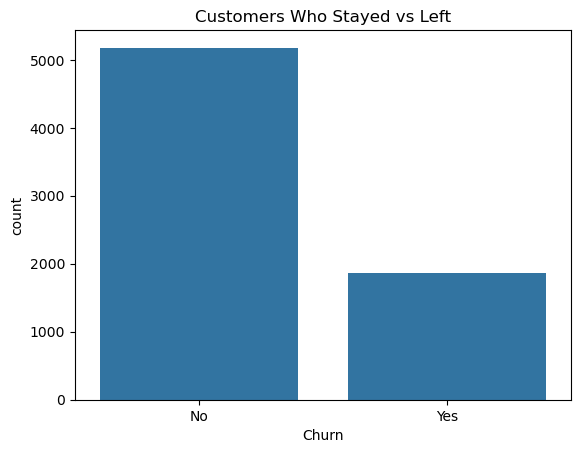

In [3]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="Churn")
plt.title("Customers Who Stayed vs Left")
plt.show()

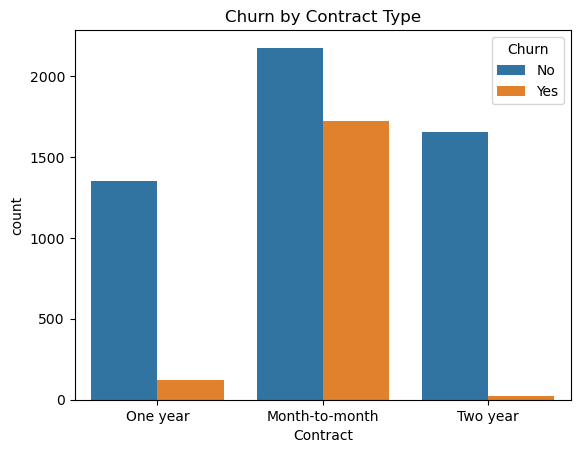

In [4]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.show()

In [5]:
for col in ["Contract", "InternetService", "PaymentMethod", "tenure_group"]:
    print(df.groupby(col)["churn_flag"].mean().mul(100).round(1))
    print()

Contract
Month-to-month    44.2
One year           8.3
Two year           1.3
Name: churn_flag, dtype: float64

InternetService
DSL            21.3
Fiber optic    36.3
No             14.4
Name: churn_flag, dtype: float64

PaymentMethod
Bank transfer (automatic)    17.2
Credit card (automatic)      20.1
Electronic check             40.8
Mailed check                 22.8
Name: churn_flag, dtype: float64

tenure_group
0-12 months     51.2
13-24 months    37.4
25-48 months    17.1
49+ months       4.7
Name: churn_flag, dtype: float64



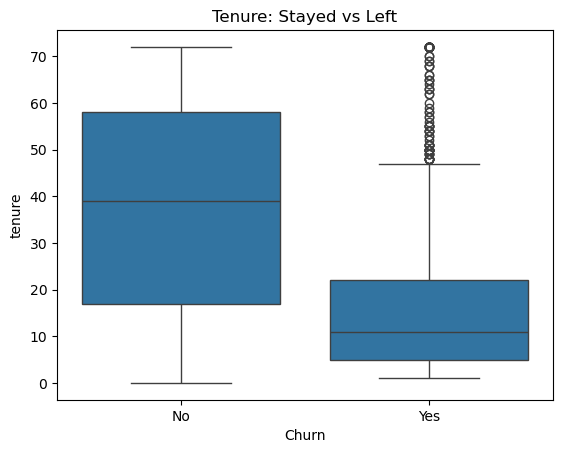

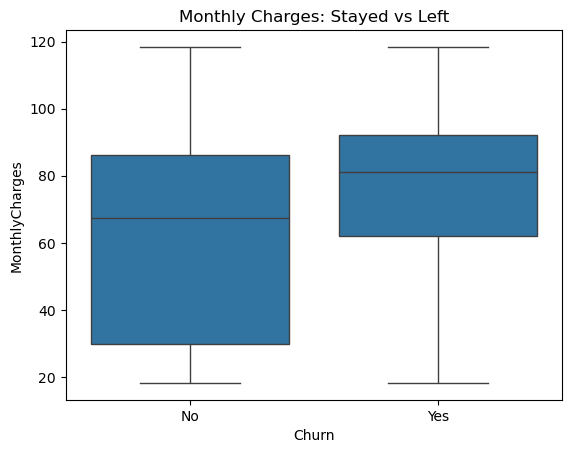

In [6]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure: Stayed vs Left")
plt.show()

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges: Stayed vs Left")
plt.show()

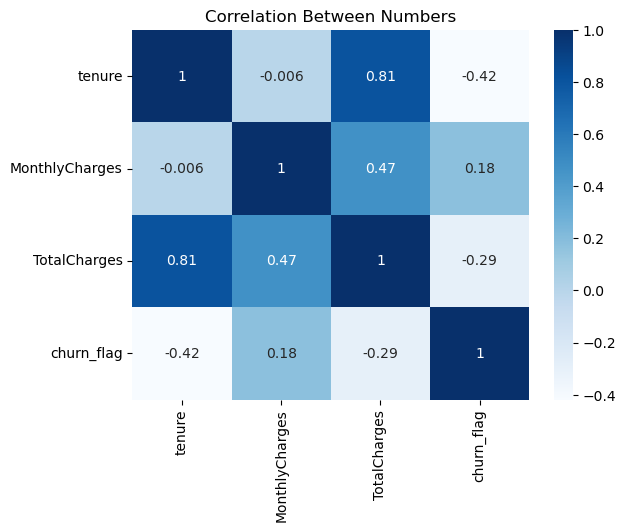

In [7]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "churn_flag"]]
sns.heatmap(num.corr(), annot=True, cmap="Blues")
plt.title("Correlation Between Numbers")
plt.show()